# Startup Success Prediction – BAN1023 Final Project

In this notebook I build a simple data science project to predict whether a startup will succeed or fail using the "Startup Success Prediction" dataset from Kaggle. The goal is to follow all phases of a data science project: loading the data, cleaning it, exploring patterns, training models, and evaluating results.

!pip install seaborn


In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

sns.set(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)


## Load and Inspect Data

In this section I load the startup dataset from a CSV file into a pandas DataFrame and check the basic structure. This helps me see what columns exist and if the data loaded correctly.


import pandas as pd

df = pd.read_csv("/Users/geraldvelas/Downloads/startup_data.csv")
df.shape


## First Look at the Data

Here I check the first rows and the column names of the dataset to understand what information is available about each startup.


In [14]:
df.head()


,Unnamed: 0,state_code,latitude,longitude,zip_code,id,city,Unnamed: 6,name,labels,...,object_id,has_VC,has_angel,has_roundA,has_roundB,has_roundC,has_roundD,avg_participants,is_top500,status
0,1005,CA,42.358880,-71.056820,92101,c:6669,San Diego,NaN,Bandsintown,1,...,c:6669,0,1,0,0,0,0,1.0000,0,acquired
1,204,CA,37.238916,-121.973718,95032,c:16283,Los Gatos,NaN,TriCipher,1,...,c:16283,1,0,0,1,1,1,4.7500,1,acquired
2,1001,CA,32.901049,-117.192656,92121,c:65620,San Diego,San Diego CA 92121,Plixi,1,...,c:65620,0,0,1,0,0,0,4.0000,1,acquired
3,738,CA,37.320309,-122.050040,95014,c:42668,Cupertino,Cupertino CA 95014,Solidcore Systems,1,...,c:42668,0,0,0,1,1,1,3.3333,1,acquired
4,1002,CA,37.779281,-122.419236,94105,c:65806,San Francisco,San Francisco CA 94105,Inhale Digital,0,...,c:65806,1,1,0,0,0,0,1.0000,1,closed


In [15]:
df.columns


Index(['Unnamed: 0', 'state_code', 'latitude', 'longitude', 'zip_code', 'id',
       'city', 'Unnamed: 6', 'name', 'labels', 'founded_at', 'closed_at',
       'first_funding_at', 'last_funding_at', 'age_first_funding_year',
       'age_last_funding_year', 'age_first_milestone_year',
       'age_last_milestone_year', 'relationships', 'funding_rounds',
       'funding_total_usd', 'milestones', 'state_code.1', 'is_CA', 'is_NY',
       'is_MA', 'is_TX', 'is_otherstate', 'category_code', 'is_software',
       'is_web', 'is_mobile', 'is_enterprise', 'is_advertising',
       'is_gamesvideo', 'is_ecommerce', 'is_biotech', 'is_consulting',
       'is_othercategory', 'object_id', 'has_VC', 'has_angel', 'has_roundA',
       'has_roundB', 'has_roundC', 'has_roundD', 'avg_participants',
       'is_top500', 'status'],
      dtype='object')

## Select Main Columns

Here I keep only the columns that are useful for predicting startup success, such as status, funding, sector and basic location. This makes the dataset easier to work with in the next steps.


In [16]:
use_cols = [
    "status",
    "funding_rounds",
    "funding_total_usd",
    "founded_at",
    "age_first_funding_year",
    "age_last_funding_year",
    "category_code",
    "state_code",
    "has_VC",
    "has_angel",
    "is_top500"
]

df_small = df[use_cols].copy()
df_small.head()


,status,funding_rounds,funding_total_usd,founded_at,age_first_funding_year,age_last_funding_year,category_code,state_code,has_VC,has_angel,is_top500
0,acquired,3,375000,1/1/2007,2.2493,3.0027,music,CA,0,1,0
1,acquired,4,40100000,1/1/2000,5.1260,9.9973,enterprise,CA,1,0,1
2,acquired,1,2600000,3/18/2009,1.0329,1.0329,web,CA,0,0,1
3,acquired,3,40000000,1/1/2002,3.1315,5.3151,software,CA,0,0,1
4,closed,2,1300000,8/1/2010,0.0000,1.6685,games_video,CA,1,1,1


## Create Binary Target Variable

In this step I convert the original `status` column into a simple binary label called `success`. I treat startups that are operating, acquired or IPO as successful, and closed startups as failures. This gives me a clear 0/1 target for classification.


In [17]:
df_small["status"].value_counts()


status
acquired    597
closed      326
Name: count, dtype: int64

In [18]:
def map_status_to_success(status):
    status = str(status).lower()
    if status in ["operating", "acquired", "ipo"]:
        return 1
    elif status in ["closed"]:
        return 0
    else:
        # treat anything else as failure for simplicity
        return 0

df_small["success"] = df_small["status"].apply(map_status_to_success)

df_small["success"].value_counts()


success
1    597
0    326
Name: count, dtype: int64

## Handle Missing Values and Prepare Numeric Features

Here I check for missing values in the main numeric columns and fill them where needed. I also convert funding to a numeric type and create a log-transformed version to reduce skew.


In [19]:
df_small.isna().sum()


status                    0
funding_rounds            0
funding_total_usd         0
founded_at                0
age_first_funding_year    0
age_last_funding_year     0
category_code             0
state_code                0
has_VC                    0
has_angel                 0
is_top500                 0
success                   0
dtype: int64

In [20]:
# convert funding to numeric (some datasets store it as string)
df_small["funding_total_usd"] = pd.to_numeric(df_small["funding_total_usd"], errors="coerce")
df_small["funding_rounds"] = pd.to_numeric(df_small["funding_rounds"], errors="coerce")

# create an age proxy: use age_last_funding_year if available, otherwise age_first_funding_year
df_small["age_proxy"] = df_small["age_last_funding_year"]
df_small["age_proxy"] = df_small["age_proxy"].fillna(df_small["age_first_funding_year"])

# list of numeric columns we will keep
num_cols = ["funding_total_usd", "funding_rounds", "age_proxy"]

# fill missing numeric values with median
for col in num_cols:
    df_small[col] = df_small[col].fillna(df_small[col].median())

# create log funding
df_small["log_funding"] = np.log1p(df_small["funding_total_usd"])

df_small[num_cols + ["log_funding"]].describe()


,funding_total_usd,funding_rounds,age_proxy,log_funding
count,9.230000e+02,923.000000,923.000000,923.000000
mean,2.541975e+07,2.310943,3.931456,15.745752
std,1.896344e+08,1.390922,2.967910,1.814800
min,1.100000e+04,1.000000,-9.046600,9.305741
25%,2.725000e+06,1.000000,1.669850,14.817937
50%,1.000000e+07,2.000000,3.528800,16.118096
75%,2.472500e+07,3.000000,5.560250,17.023325
max,5.700000e+09,10.000000,21.895900,22.463732


## Exploratory Data Analysis (Class Balance and Funding)

In this part I quickly check how many successful and failed startups there are, and I compare funding between the two groups. This helps me see basic patterns before building any models.


In [21]:
df_small["success"].value_counts()


success
1    597
0    326
Name: count, dtype: int64

In [22]:
df_small.groupby("success")[["funding_rounds", "funding_total_usd", "log_funding"]].mean()


,funding_rounds,funding_total_usd,log_funding
success,,,
0,1.923313,1.511532e+07,15.010163
1,2.522613,3.104662e+07,16.147431


### Funding Distribution by Success

Here I visualize how log-transformed funding is distributed for successful and failed startups. This makes it easier to see if successful startups tend to raise more capital.


In [23]:
import seaborn as sns
sns.set(style="whitegrid")


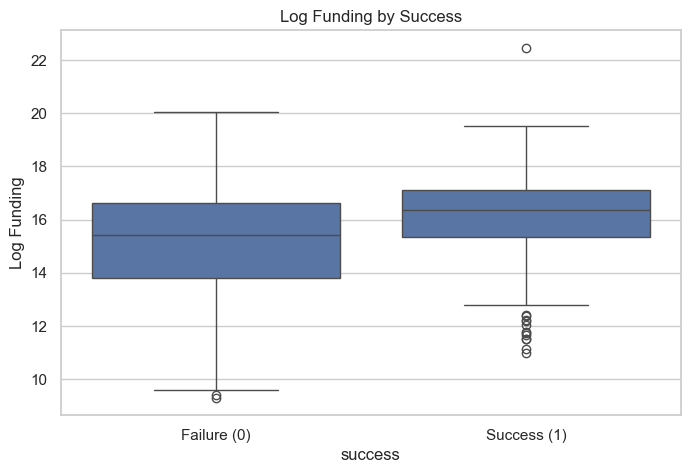

In [24]:
import seaborn as sns

sns.boxplot(x="success", y="log_funding", data=df_small)
plt.xticks([0, 1], ["Failure (0)", "Success (1)"])
plt.ylabel("Log Funding")
plt.title("Log Funding by Success")
plt.show()


## Prepare Features and Train/Test Split

Here I select the final features for the model, convert categorical variables into dummy variables, and split the data into a training set and a test set. The training set is used to fit the models and the test set is used to evaluate how well they generalize.


In [25]:
feature_cols = [
    "funding_rounds",
    "log_funding",
    "age_proxy",
    "category_code",
    "state_code",
    "has_VC",
    "has_angel",
    "is_top500"
]

df_model = df_small[feature_cols + ["success"]].copy()
df_model.head()


,funding_rounds,log_funding,age_proxy,category_code,state_code,has_VC,has_angel,is_top500,success
0,3,12.834684,3.0027,music,CA,0,1,0,1
1,4,17.506887,9.9973,enterprise,CA,1,0,1,1
2,1,14.771022,1.0329,web,CA,0,0,1,1
3,3,17.504390,5.3151,software,CA,0,0,1,1
4,2,14.077876,1.6685,games_video,CA,1,1,1,0


In [26]:
X = pd.get_dummies(
    df_model[feature_cols],
    columns=["category_code", "state_code"],
    drop_first=True
)

y = df_model["success"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape


((646, 74), (277, 74))

## Logistic Regression Model

In this step I train a Logistic Regression model as a baseline classifier. I first scale the main numeric features and then fit the model on the training set. After that I evaluate its accuracy and other metrics on the test set.


In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# numeric columns to scale
num_cols_model = ["funding_rounds", "log_funding", "age_proxy"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols_model] = scaler.fit_transform(X_train[num_cols_model])
X_test_scaled[num_cols_model] = scaler.transform(X_test[num_cols_model])

# train logistic regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# predictions
y_pred_lr = log_reg.predict(X_test_scaled)

# evaluation
acc_lr = accuracy_score(y_test, y_pred_lr)
print("Logistic Regression Accuracy:", acc_lr)
print("\nClassification Report (Logistic Regression):")
print(classification_report(y_test, y_pred_lr))


Logistic Regression Accuracy: 0.7148014440433214

Classification Report (Logistic Regression):
              precision    recall  f1-score   support

           0       0.62      0.50      0.55        98
           1       0.75      0.83      0.79       179

    accuracy                           0.71       277
   macro avg       0.69      0.67      0.67       277
weighted avg       0.71      0.71      0.71       277



### Confusion Matrix – Logistic Regression

The confusion matrix shows how many startups in each true class (success or failure) are correctly or incorrectly classified by the logistic regression model.


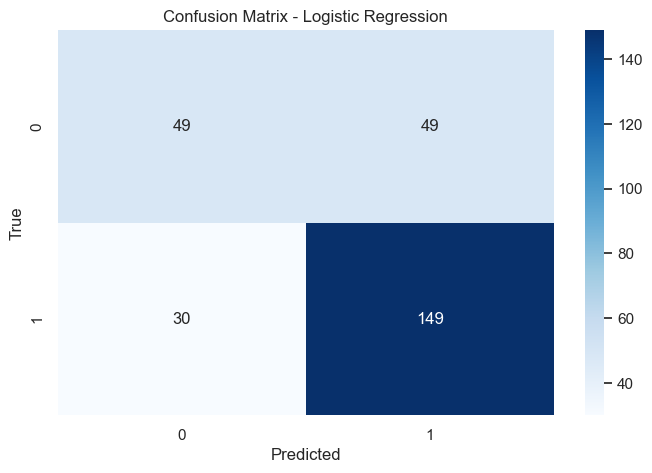

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


## Random Forest Model

Here I train a Random Forest classifier on the same features. This model can capture non-linear relationships and interactions between variables. I then compare its performance with the logistic regression baseline.


In [29]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

acc_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", acc_rf)
print("\nClassification Report (Random Forest):")
print(classification_report(y_test, y_pred_rf))


Random Forest Accuracy: 0.703971119133574

Classification Report (Random Forest):
              precision    recall  f1-score   support

           0       0.60      0.50      0.54        98
           1       0.75      0.82      0.78       179

    accuracy                           0.70       277
   macro avg       0.67      0.66      0.66       277
weighted avg       0.70      0.70      0.70       277



### Confusion Matrix – Random Forest

This confusion matrix shows how many startups of each true class are correctly or incorrectly classified by the Random Forest model.


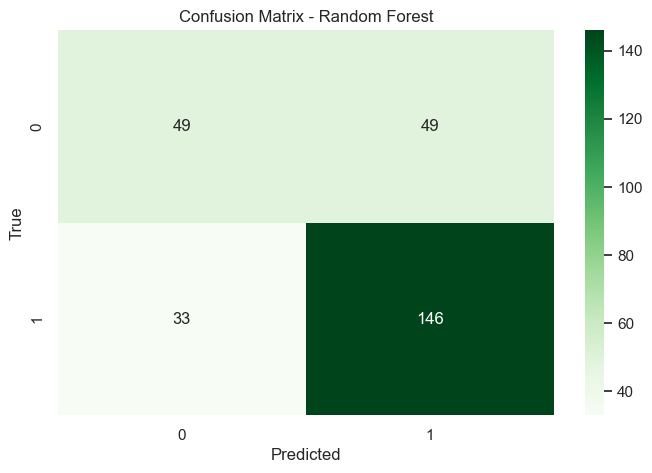

In [30]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens")
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


### Feature Importance – Random Forest

I also look at the feature importances from the Random Forest to understand which variables contribute most to predicting startup success (for example funding rounds, log funding, sector and location).


In [31]:
importances = pd.Series(rf.feature_importances_, index=X.columns)
top_importances = importances.sort_values(ascending=False).head(15)
top_importances


age_proxy                 0.227079
log_funding               0.222393
funding_rounds            0.083637
is_top500                 0.050225
has_VC                    0.034563
state_code_CA             0.026040
category_code_software    0.021059
has_angel                 0.020663
category_code_web         0.019400
category_code_hardware    0.017805
category_code_mobile      0.016950
state_code_NY             0.014377
state_code_MA             0.013754
state_code_TX             0.013502
category_code_other       0.013155
dtype: float64

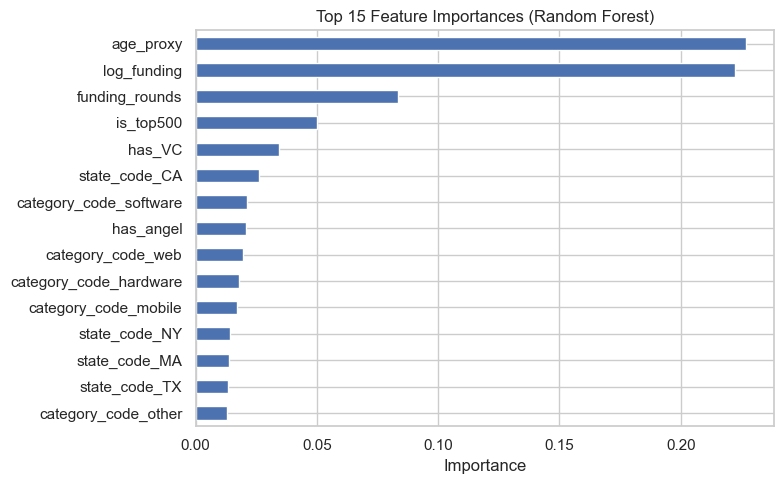

In [32]:
top_importances.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 15 Feature Importances (Random Forest)")
plt.tight_layout()
plt.show()


## Limitations and Conclusion

In this project I used a public startup dataset from Kaggle to predict a simple binary `success` label using basic machine learning models. After cleaning the data, creating a `success` target, and engineering features like `log_funding` and an age proxy, I trained two models: Logistic Regression and Random Forest.[web:2][web:21]

The Logistic Regression model reached about 71% accuracy on the test set, while the Random Forest reached about 70%. Both models performed better on the success class (1) than on the failure class (0), which shows that failed startups are harder to detect correctly.[web:12][web:29] The feature importance from the Random Forest suggests that funding rounds, total funding (log scale), age, and some sector and location indicators are among the most important predictors, which matches what I saw in the exploratory analysis and in the literature about venture capital and startup outcomes.[web:5][web:30]

Moreover, I only used two simple models with default hyperparameters, so there is room to try more advanced methods or better tuning in the future. Still, this project helped me practice all phases of a data science workflow and see how real startup data can be turned into a model that supports, but does not replace, human judgement about investment decisions.[file:51][web:42]
